# RAG para análise de editais da FINEP (v2)
**DCA0133 – Aprendizagem de Máquina e Mineração de Dados (2026.2)** · Trabalho: estudo de Transformers/LLM

Sistema de perguntas e respostas sobre editais da FINEP com **Retrieval-Augmented Generation (RAG)**.

| Etapa | Papel do Transformer |
|---|---|
| Embeddings dos trechos e da pergunta | Encoder (BERT-like, `multilingual-e5`) |
| *Reranking* dos trechos (opcional) | Cross-encoder (encoder que lê pergunta + trecho juntos) |
| Geração da resposta | Decoder (LLM: Qwen local e/ou Claude via API) |

### O que mudou na v2
- **Avaliação refeita:** perguntas específicas por edital, com gabarito, perguntas "sem resposta no edital" e **nota manual** (0 / 0,5 / 1) por uma interface lado a lado (RAG × sem RAG).
- **Métricas de recuperação melhores:** Hit@k por página/regex e **MRR**.
- **Busca híbrida (BM25 + vetorial)** e **reranker Transformer**, comparados na ablação.
- **Comparação de LLMs** (ex.: Qwen 1,5B × 3B × Claude) para discutir o efeito do tamanho do Transformer.
- Ferramentas para montar o gabarito (`procurar`, `explorar`), correção dos gráficos e **resultados salvos no Drive** (CSV e PNG para os slides).

### Índice
1. Setup e configuração · 2. Carga dos editais · 3. Extração e análise exploratória · 4. Chunking · 5. Embeddings, BM25 e índice · 6. Espaço de embeddings · 7. Self-attention · 8. Recuperação e geração · 9. Avaliação · 10. Ablação · 11. Interface · 12. Resumo e conclusões

## 1. Setup e configuração

In [1]:
!pip install -q pymupdf sentence-transformers faiss-cpu rank_bm25 ipywidgets anthropic transformers accelerate scikit-learn pandas matplotlib

In [2]:
import os, re, glob, time, getpass, warnings, html, unicodedata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import fitz  # PyMuPDF
import faiss
from sentence_transformers import SentenceTransformer

warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25})

# ======================= CONFIGURAÇÃO (edite aqui) =======================
PASTA_PDFS = "/content/drive/MyDrive/Acadêmico/2026.2/Aprendizado de Maquína e Mineração de Dados/Trabalho 2 unidade/Trabalho Lista/editais_finep"

EMBEDDING_MODEL = "intfloat/multilingual-e5-base"
CHUNK_SIZE      = 1000          # caracteres por trecho
CHUNK_OVERLAP   = 200           # sobreposição entre trechos
TOP_K           = 5             # trechos enviados ao LLM
EXTRAIR_TABELAS = True

MODO_BUSCA = "hibrido"          # "vetorial" | "bm25" | "hibrido" | "hibrido+rerank"
RERANKER   = "cross-encoder/mmarco-mMiniLMv2-L12-H384-v1"   # cross-encoder multilíngue

# LLMs disponíveis: nome -> (backend, modelo). backend: "hf_local" (GPU do Colab) ou "anthropic" (API)
LLMS = {
    "qwen-1.5b": ("hf_local",  "Qwen/Qwen2.5-1.5B-Instruct"),
    "qwen-3b":   ("hf_local",  "Qwen/Qwen2.5-3B-Instruct"),
    "claude":    ("anthropic", "claude-sonnet-5-5"),
}
LLM_PADRAO   = "qwen-3b"        # usado no teste e na interface
LLMS_AVALIAR = ["qwen-3b"]      # ex.: ["qwen-1.5b", "qwen-3b"] para comparar tamanhos de modelo
# =========================================================================

PASTA_SAIDA = os.path.join(os.path.dirname(PASTA_PDFS), "resultados_rag")   # CSVs e figuras (criada após montar o Drive)
SEED = 42
np.random.seed(SEED)
print("Configuração carregada.")

/usr/local/lib/python3.13/dist-packages/fitz/__init__.py:17: FutureWarning: The `fitz` API is deprecated and will be removed in future. Use `import pymupdf` instead.
  warnings.warn(


Configuração carregada.


## 2. Carga dos editais (Google Drive)
Monta o Drive, lê os PDFs de `PASTA_PDFS` e cria a pasta de resultados (`resultados_rag`, ao lado da pasta dos editais). Se não houver PDFs, oferece upload manual.

In [4]:
try:
    from google.colab import drive
    drive.mount("/content/drive")
    EM_COLAB = True
except ImportError:
    EM_COLAB = False

PDFS = sorted(glob.glob(os.path.join(PASTA_PDFS, "**", "*.pdf"), recursive=True))

if not PDFS:
    print(f"Nenhum PDF encontrado em '{PASTA_PDFS}'.")
    if EM_COLAB:
        print("Verifique o caminho ou faça upload manual dos PDFs:")
        from google.colab import files
        os.makedirs("editais_upload", exist_ok=True)
        for nome, conteudo in files.upload().items():
            open(os.path.join("editais_upload", nome), "wb").write(conteudo)
        PDFS = sorted(glob.glob("editais_upload/*.pdf"))
    else:
        raise SystemExit("Coloque os PDFs na pasta indicada em PASTA_PDFS.")

try:
    os.makedirs(PASTA_SAIDA, exist_ok=True)
except Exception:
    PASTA_SAIDA = "resultados_rag"
    os.makedirs(PASTA_SAIDA, exist_ok=True)

print(f"{len(PDFS)} edital(is) encontrado(s):")
for p in PDFS:
    print(" •", os.path.basename(p))
print("Resultados serão salvos em:", PASTA_SAIDA)

Mounted at /content/drive
3 edital(is) encontrado(s):
 • 07_02_2025_CT_MCTI2025_Edital.pdf
 • 23_12_2025_Proinfra2025Expansao_Edital.pdf
 • Edital Carta Convite Manutenção Unid. Vinc. MCTI.pdf
Resultados serão salvos em: /content/drive/MyDrive/Acadêmico/2026.2/Aprendizado de Maquína e Mineração de Dados/Trabalho 2 unidade/Trabalho Lista/resultados_rag


## 3. Extração de texto e análise exploratória

In [5]:
def limpar_texto(t):
    t = re.sub(r"(\w)-\n(\w)", r"\1\2", t)
    t = re.sub(r"[ \t]+", " ", t)
    t = re.sub(r"\n{3,}", "\n\n", t)
    return t.strip()

def extrair_pdf(caminho, tabelas=True):
    doc = fitz.open(caminho)
    nome = os.path.basename(caminho)
    paginas, n_tabelas = [], 0
    for i, pg in enumerate(doc):
        texto = limpar_texto(pg.get_text("text"))
        if tabelas:
            try:
                for tb in pg.find_tables().tables:
                    md_tab = tb.to_markdown()
                    if md_tab and len(md_tab) > 30:
                        texto += "\n\n[TABELA]\n" + md_tab
                        n_tabelas += 1
            except Exception:
                pass
        paginas.append({"arquivo": nome, "pagina": i + 1, "texto": texto})
    return paginas, n_tabelas

paginas, tabelas_por_doc = [], {}
for p in PDFS:
    pgs, nt = extrair_pdf(p, EXTRAIR_TABELAS)
    paginas += pgs
    tabelas_por_doc[os.path.basename(p)] = nt

df_pag = pd.DataFrame(paginas)
df_pag["n_chars"] = df_pag["texto"].str.len()
DOCS = sorted(df_pag["arquivo"].unique())
print(f"{len(df_pag)} páginas extraídas de {len(DOCS)} edital(is).")
df_pag.groupby("arquivo").agg(paginas=("pagina", "count"), caracteres=("n_chars", "sum"),
                               media_chars_pag=("n_chars", "mean")).round(0)

73 páginas extraídas de 3 edital(is).


,paginas,caracteres,media_chars_pag
arquivo,,,
07_02_2025_CT_MCTI2025_Edital.pdf,26,71150,2737.0
23_12_2025_Proinfra2025Expansao_Edital.pdf,27,77789,2881.0
Edital Carta Convite Manutenção Unid. Vinc. MCTI.pdf,20,40898,2045.0


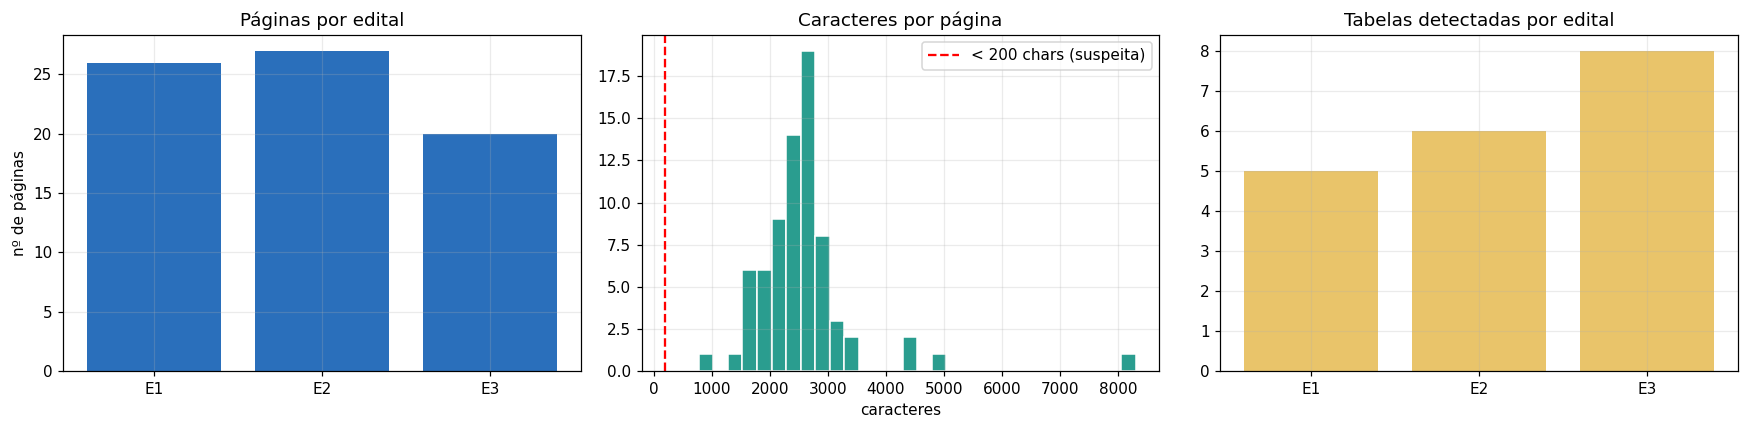

E1 = 07_02_2025_CT_MCTI2025_Edital.pdf
E2 = 23_12_2025_Proinfra2025Expansao_Edital.pdf
E3 = Edital Carta Convite Manutenção Unid. Vinc. MCTI.pdf

Páginas com pouco texto (possível imagem/escaneada): 0


In [6]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
contagem = df_pag.groupby("arquivo")["pagina"].count()
ax[0].bar(range(len(contagem)), contagem.values, color="#2a6fbb")
ax[0].set_xticks(range(len(contagem))); ax[0].set_xticklabels([f"E{i+1}" for i in range(len(contagem))])
ax[0].set_title("Páginas por edital"); ax[0].set_ylabel("nº de páginas")

ax[1].hist(df_pag["n_chars"], bins=30, color="#2a9d8f", edgecolor="white")
ax[1].axvline(200, color="red", ls="--", label="< 200 chars (suspeita)")
ax[1].set_title("Caracteres por página"); ax[1].set_xlabel("caracteres"); ax[1].legend()

tb = pd.Series(tabelas_por_doc)
ax[2].bar(range(len(tb)), tb.values, color="#e9c46a")
ax[2].set_xticks(range(len(tb))); ax[2].set_xticklabels([f"E{i+1}" for i in range(len(tb))])
ax[2].set_title("Tabelas detectadas por edital")
plt.tight_layout()
plt.savefig(os.path.join(PASTA_SAIDA, "fig_exploratoria.png"), dpi=200, bbox_inches="tight")
plt.show()

for i, d in enumerate(DOCS):
    print(f"E{i+1} = {d}")
print(f"\nPáginas com pouco texto (possível imagem/escaneada): {(df_pag['n_chars'] < 200).sum()}")

## 4. Divisão em trechos (*chunking*)
Cada trecho guarda **arquivo, página e seção**. Correção da v2: o título da seção agora é normalizado (sem quebras de linha). Também há a função `casa_doc`, que permite filtrar por **parte do nome** do edital (ex.: `"Proinfra"`).

In [7]:
RE_TITULO = re.compile(r"^\s*(\d{1,2}(?:\.\d{1,2})*\.?\s+[A-ZÁÉÍÓÚÂÊÔÃÕÇ][^\n]{3,90})$", re.MULTILINE)

def casa_doc(arquivo, filtro):
    """True se não há filtro ou se o filtro (parte do nome) aparece no nome do arquivo."""
    return (not filtro) or (filtro.lower() in arquivo.lower())

def dividir_texto(texto, tamanho, sobreposicao):
    if len(texto) <= tamanho:
        return [(0, texto)] if len(texto) > 50 else []
    partes, ini = [], 0
    while ini < len(texto):
        fim = min(ini + tamanho, len(texto))
        if fim < len(texto):
            corte = max(texto.rfind(". ", ini, fim), texto.rfind("\n", ini, fim))
            if corte > ini + tamanho * 0.5:
                fim = corte + 1
        trecho = texto[ini:fim].strip()
        if len(trecho) > 50:
            partes.append((ini, trecho))
        if fim >= len(texto):
            break
        ini = max(fim - sobreposicao, ini + 1)
    return partes

def criar_chunks(paginas, tamanho=CHUNK_SIZE, sobreposicao=CHUNK_OVERLAP):
    chunks, secao_atual, doc_atual = [], "Início", None
    for pg in paginas:
        if pg["arquivo"] != doc_atual:
            doc_atual, secao_atual = pg["arquivo"], "Início"
        titulos = [(m.start(), re.sub(r"\s+", " ", m.group(1)).strip()) for m in RE_TITULO.finditer(pg["texto"])]
        for pos, trecho in dividir_texto(pg["texto"], tamanho, sobreposicao):
            ativos = [t for p, t in titulos if p <= pos]
            sec = ativos[-1] if ativos else secao_atual
            chunks.append({"id": len(chunks), "arquivo": pg["arquivo"], "pagina": pg["pagina"],
                           "secao": sec, "texto": trecho})
        if titulos:
            secao_atual = titulos[-1][1]
    return chunks

CHUNKS = criar_chunks(paginas)
df_chunks = pd.DataFrame(CHUNKS)
df_chunks["n_chars"] = df_chunks["texto"].str.len()
print(f"{len(CHUNKS)} trechos criados (tamanho={CHUNK_SIZE}, sobreposição={CHUNK_OVERLAP}).")
df_chunks[["arquivo", "pagina", "secao", "n_chars"]].head()

267 trechos criados (tamanho=1000, sobreposição=200).


,arquivo,pagina,secao,n_chars
0,07_02_2025_CT_MCTI2025_Edital.pdf,1,Início,917
1,07_02_2025_CT_MCTI2025_Edital.pdf,1,1. OBJETIVO,992
2,07_02_2025_CT_MCTI2025_Edital.pdf,1,2.1.2. Comitê Gestor: grupo responsável por tr...,883
3,07_02_2025_CT_MCTI2025_Edital.pdf,2,2.1.4. Confecção de projeto básico ou executiv...,947
4,07_02_2025_CT_MCTI2025_Edital.pdf,2,"2.1.6.1. O valor poderá englobar acessórios, i...",979


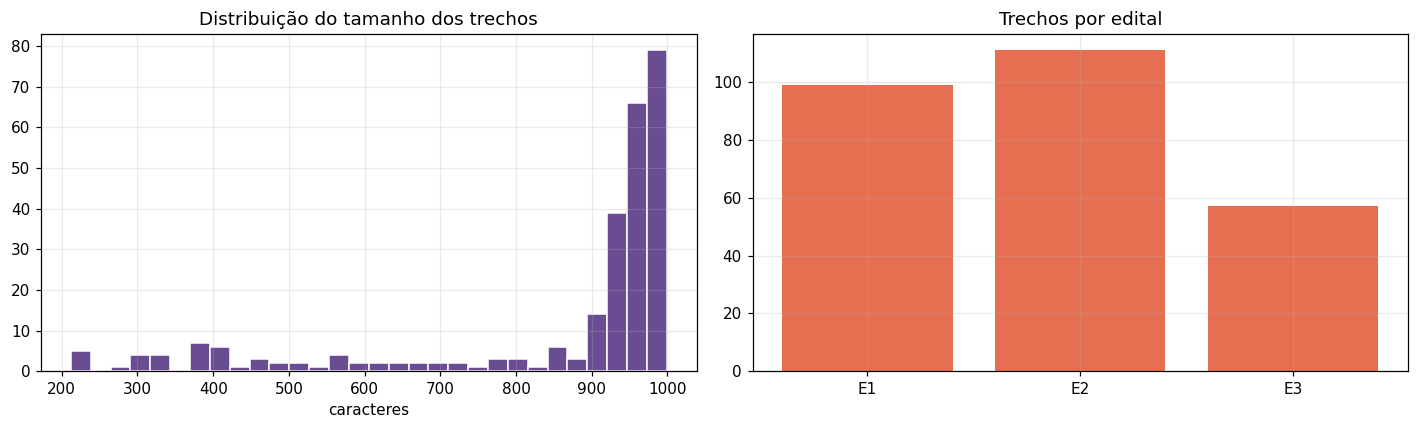

Exemplo de trecho:
[23_12_2025_Proinfra2025Expansao_Edital.pdf | p.9 | 5.6.3.1. A infraestrutura mínima deverá ser comprovada por meio de relatório fotográfico]
3.1. 
A infraestrutura mínima deverá ser comprovada por meio de relatório fotográfico 
do local, conforme Anexo VII. 
5.6.3.2. 
É permitida a solicitação de equipamentos para alocação em contêineres 
enquadrados como equipamento, solicitados no âmbito deste edital, conforme item 
2.1.7. 
5.6.3.3. 
No caso de solicitação de equipamentos para um local/estrutura em construção 
ou ainda inexistente ou para um local sem infraestrutura mínima, os equipamentos 
nesta condição deverão ser eliminados....


In [8]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].hist(df_chunks["n_chars"], bins=30, color="#6a4c93", edgecolor="white")
ax[0].set_title("Distribuição do tamanho dos trechos"); ax[0].set_xlabel("caracteres")
por_doc = df_chunks.groupby("arquivo").size()
ax[1].bar(range(len(por_doc)), por_doc.values, color="#e76f51")
ax[1].set_xticks(range(len(por_doc))); ax[1].set_xticklabels([f"E{i+1}" for i in range(len(por_doc))])
ax[1].set_title("Trechos por edital")
plt.tight_layout(); plt.show()

ex = CHUNKS[len(CHUNKS)//2]
print(f"Exemplo de trecho:\n[{ex['arquivo']} | p.{ex['pagina']} | {ex['secao']}]\n{ex['texto'][:600]}...")

## 5. Embeddings, BM25 e índice de busca
Quatro **modos de busca**, comparados na seção 10:

| Modo | Como funciona |
|---|---|
| `vetorial` | Encoder Transformer (`multilingual-e5`) → vetores normalizados → similaridade do cosseno (FAISS) |
| `bm25` | Busca lexical clássica (palavras em comum, ponderadas por raridade) |
| `hibrido` | Combina os dois rankings por *Reciprocal Rank Fusion* (RRF) |
| `hibrido+rerank` | Pega os 20 melhores do híbrido e reordena com um **cross-encoder Transformer**, que lê pergunta e trecho *juntos* (self-attention sobre o par), mais preciso que comparar dois vetores prontos |

A busca vetorial pode falhar quando o edital usa outras palavras (ex.: "vigência" em vez de "prazo de execução"); a lexical falha com sinônimos. Por isso a combinação.

In [9]:
STOP = set("a o as os de da do das dos e em na no nas nos um uma para por com que se ao aos ou qual quais quem como sao ser foi deve".split())

def tokenizar(t):
    t = unicodedata.normalize("NFKD", t.lower())
    t = "".join(ch for ch in t if not unicodedata.combining(ch))
    return [w for w in re.findall(r"\w+", t) if w not in STOP]

_cache_modelos = {}
def carregar_modelo(nome):
    if nome not in _cache_modelos:
        _cache_modelos[nome] = SentenceTransformer(nome)
    return _cache_modelos[nome]

def codificar(nome_modelo, textos, tipo="passage"):
    prefixo = f"{tipo}: " if "e5" in nome_modelo.lower() else ""
    emb = carregar_modelo(nome_modelo).encode([prefixo + t for t in textos], normalize_embeddings=True,
                                              batch_size=32, show_progress_bar=len(textos) > 50)
    return np.asarray(emb, dtype="float32")

_reranker = {"modelo": None, "falhou": False}
def get_reranker():
    if _reranker["modelo"] is None and not _reranker["falhou"]:
        try:
            from sentence_transformers import CrossEncoder
            _reranker["modelo"] = CrossEncoder(RERANKER)
        except Exception as e:
            _reranker["falhou"] = True
            print("Reranker indisponível, usando só a busca híbrida:", e)
    return _reranker["modelo"]

MODOS = ["vetorial", "bm25", "hibrido", "hibrido+rerank"]

class IndiceVetorial:
    def __init__(self, chunks, nome_modelo=EMBEDDING_MODEL):
        from rank_bm25 import BM25Okapi
        self.chunks, self.nome_modelo = chunks, nome_modelo
        self.emb = codificar(nome_modelo, [c["texto"] for c in chunks], "passage")
        self.index = faiss.IndexFlatIP(self.emb.shape[1])
        self.index.add(self.emb)
        self.bm25 = BM25Okapi([tokenizar(c["texto"]) for c in chunks])

    def buscar(self, pergunta, k=TOP_K, documento=None, modo="vetorial", k_candidatos=20):
        assert modo in MODOS, f"modo deve ser um de {MODOS}"
        n = len(self.chunks)
        ids = np.array([i for i, c in enumerate(self.chunks) if casa_doc(c["arquivo"], documento)])
        if len(ids) == 0:
            return []
        # ranking vetorial (FAISS devolve todos os trechos ordenados)
        q = codificar(self.nome_modelo, [pergunta], "query")
        sc, ix = self.index.search(q, n)
        sv = np.zeros(n); sv[ix[0]] = sc[0]
        # ranking lexical
        sb = np.asarray(self.bm25.get_scores(tokenizar(pergunta)), dtype=float)

        def ranking(s):
            return ids[np.argsort(-s[ids], kind="stable")]

        rv, rb = ranking(sv), ranking(sb)
        if modo == "vetorial":
            ordem, score = rv, sv
        elif modo == "bm25":
            ordem, score = rb, sb
        else:
            rrf = np.zeros(n)
            for r in (rv, rb):
                for pos, i in enumerate(r):
                    rrf[i] += 1.0 / (60 + pos + 1)
            ordem, score = ranking(rrf), rrf
            if modo == "hibrido+rerank":
                rr = get_reranker()
                if rr is not None:
                    cand = ordem[:k_candidatos]
                    s2 = np.asarray(rr.predict([(pergunta, self.chunks[i]["texto"]) for i in cand]), dtype=float)
                    ordem = cand[np.argsort(-s2, kind="stable")]
                    score = np.zeros(n); score[cand] = s2
        return [{**self.chunks[i], "score": float(score[i]), "modo": modo} for i in ordem[:k]]

t0 = time.time()
INDICE = IndiceVetorial(CHUNKS, EMBEDDING_MODEL)
print(f"Índice criado: {INDICE.index.ntotal} vetores de dimensão {INDICE.emb.shape[1]} em {time.time()-t0:.1f}s")

modules.json:   0%|          | 0.00/387 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/179k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/57.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/694 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.11GB            

model.safetensors: downloading bytes:           |  0.00B            

... (6 outputs left out)

special_tokens_map.json:   0%|          | 0.00/280 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/200 [00:00<?, ?B/s]

Batches:   0%|          | 0/9 [00:00<?, ?it/s]

Índice criado: 267 vetores de dimensão 768 em 26.9s


## 6. Visualização do espaço de embeddings
PCA e t-SNE dos vetores dos trechos. **Correção da v2:** as cores da legenda agora coincidem com as dos pontos.

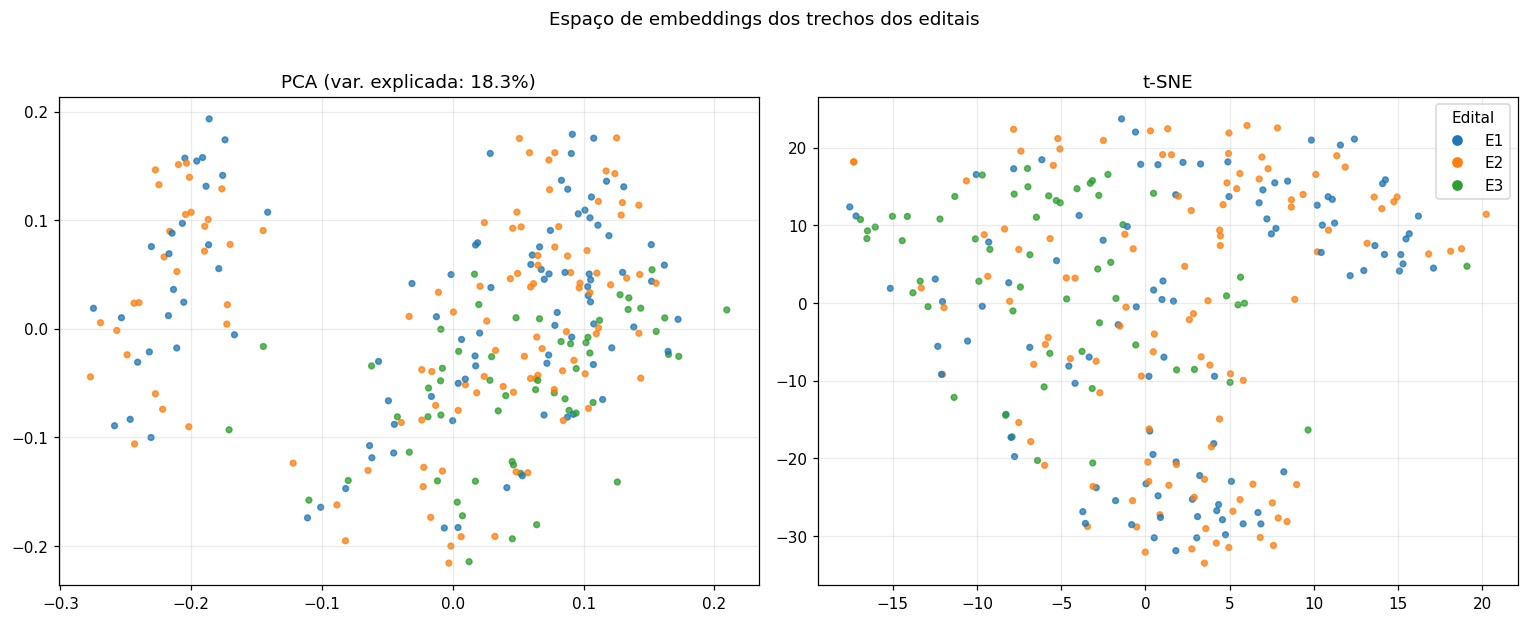

In [10]:
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

n = len(CHUNKS)
amostra = np.random.default_rng(SEED).choice(n, size=min(n, 1500), replace=False)
X = INDICE.emb[amostra]
rotulos = np.array([DOCS.index(CHUNKS[i]["arquivo"]) for i in amostra])
cores = [plt.cm.tab10(r % 10) for r in rotulos]

pca = PCA(n_components=2, random_state=SEED).fit(X)
X_pca = pca.transform(X)
X_tsne = TSNE(n_components=2, perplexity=min(30, max(5, len(X)//10)), init="pca", random_state=SEED).fit_transform(X)

fig, ax = plt.subplots(1, 2, figsize=(14, 5.5))
for j, (Z, titulo) in enumerate([(X_pca, f"PCA (var. explicada: {pca.explained_variance_ratio_.sum():.1%})"),
                                 (X_tsne, "t-SNE")]):
    ax[j].scatter(Z[:, 0], Z[:, 1], c=cores, s=14, alpha=0.75)
    ax[j].set_title(titulo)
handles = [plt.Line2D([], [], marker="o", ls="", color=plt.cm.tab10(i % 10), label=f"E{i+1}") for i in range(len(DOCS))]
ax[1].legend(handles=handles, title="Edital", loc="best")
plt.suptitle("Espaço de embeddings dos trechos dos editais", y=1.02)
plt.tight_layout()
plt.savefig(os.path.join(PASTA_SAIDA, "fig_embeddings.png"), dpi=200, bbox_inches="tight")
plt.show()

## 7. Visualização da *self-attention* (fundamentação teórica)
Pesos de atenção do BERTimbau (encoder) em uma frase típica de edital: cada linha mostra para onde cada token "olha". Mecanismo central de *Attention Is All You Need* (Vaswani et al., 2017).

config.json:   0%|          | 0.00/647 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/43.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/210k [00:00<?, ?B/s]

added_tokens.json:   0%|          | 0.00/2.00 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  438MB            

... (2 outputs left out)

[transformers] BertModel LOAD REPORT from: neuralmind/bert-base-portuguese-cased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.decoder.weight             | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


12 camadas · 12 cabeças · 20 tokens


model.safetensors: reconstructing file:   0%|          |  0.00B /  438MB            

model.safetensors: downloading bytes:           |  0.00B            

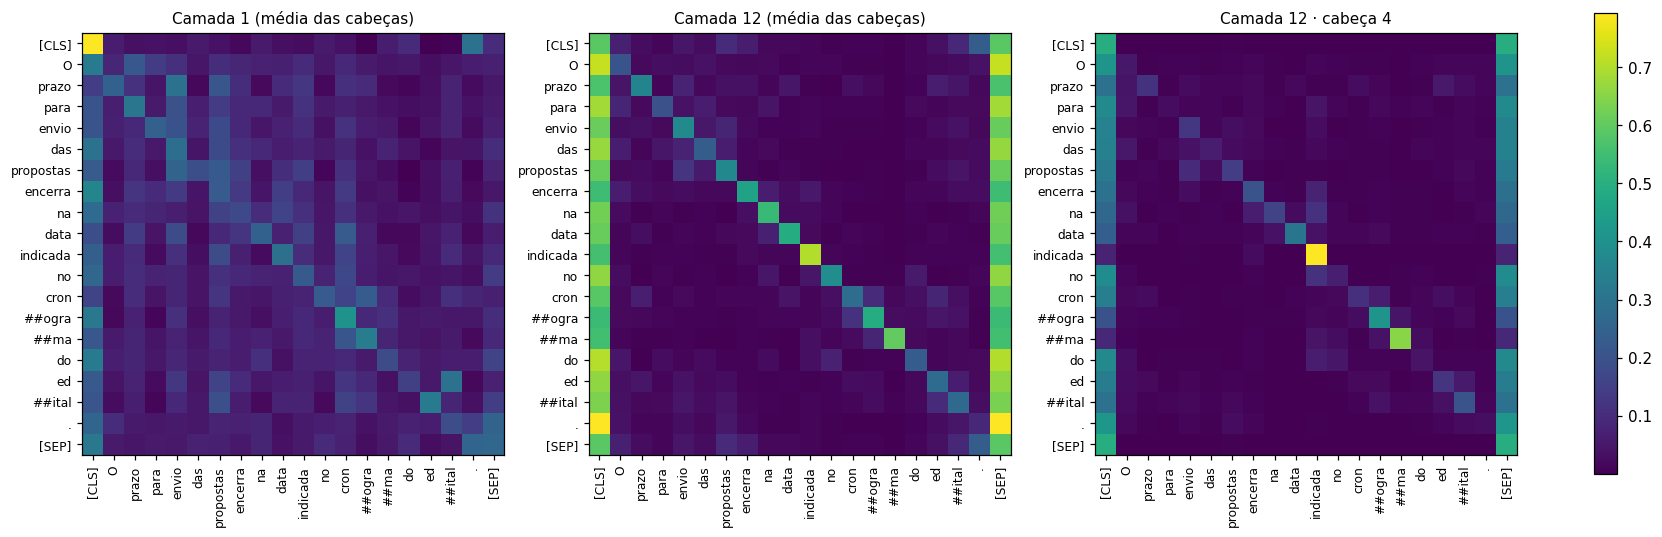

In [11]:
from transformers import AutoTokenizer, AutoModel

FRASE = "O prazo para envio das propostas encerra na data indicada no cronograma do edital."

tok_bert = AutoTokenizer.from_pretrained("neuralmind/bert-base-portuguese-cased")
bert = AutoModel.from_pretrained("neuralmind/bert-base-portuguese-cased",
                                 output_attentions=True, attn_implementation="eager").eval()
entrada = tok_bert(FRASE, return_tensors="pt")
with torch.no_grad():
    saida = bert(**entrada)
tokens = tok_bert.convert_ids_to_tokens(entrada["input_ids"][0])
atencoes = saida.attentions
print(f"{len(atencoes)} camadas · {atencoes[0].shape[1]} cabeças · {len(tokens)} tokens")

def plot_atencao(ax, matriz, titulo):
    im = ax.imshow(matriz, cmap="viridis")
    ax.set_xticks(range(len(tokens))); ax.set_xticklabels(tokens, rotation=90, fontsize=8)
    ax.set_yticks(range(len(tokens))); ax.set_yticklabels(tokens, fontsize=8)
    ax.set_title(titulo, fontsize=10); ax.grid(False)
    return im

fig, ax = plt.subplots(1, 3, figsize=(18, 6))
plot_atencao(ax[0], atencoes[0][0].mean(0).numpy(), "Camada 1 (média das cabeças)")
plot_atencao(ax[1], atencoes[-1][0].mean(0).numpy(), "Camada 12 (média das cabeças)")
im = plot_atencao(ax[2], atencoes[-1][0][3].numpy(), "Camada 12 · cabeça 4")
fig.colorbar(im, ax=ax, fraction=0.015)
plt.savefig(os.path.join(PASTA_SAIDA, "fig_atencao.png"), dpi=200, bbox_inches="tight")
plt.show()
del bert, saida, atencoes

## 8. Recuperação e geração (RAG vs. sem RAG)
**Fluxo:** pergunta → busca (modo escolhido) → top-k trechos → prompt → LLM responde citando arquivo e página.

Melhorias da v2:
- Vários LLMs configuráveis (`LLMS`), selecionados por nome.
- O prompt pede resposta curta e indicação do edital quando os trechos vêm de documentos diferentes.
- As **fontes** (arquivo e página) são anexadas **automaticamente** a partir dos trechos recuperados, sem depender de o modelo pequeno lembrar de citá-las.

In [12]:
SYSTEM_RAG = (
    "Você é um assistente especialista em editais de fomento da FINEP. "
    "Responda em português, em no máximo 4 frases, usando APENAS as informações dos trechos fornecidos. "
    "Cite a fonte no formato [arquivo, p.X]. Se os trechos vierem de editais diferentes, indique a qual edital cada informação se refere. "
    "Se a resposta não estiver nos trechos, responda exatamente: 'Não encontrei essa informação nos trechos do edital.' "
    "Nunca invente valores, datas ou percentuais."
)
SYSTEM_SEM_RAG = ("Você é um assistente especialista em editais de fomento da FINEP. "
                  "Responda em português, de forma objetiva, em no máximo 4 frases.")

def montar_prompt(pergunta, trechos):
    contexto = "\n\n".join(
        f"[Trecho {i+1} | {t['arquivo']}, p.{t['pagina']} | Seção: {t['secao']}]\n{t['texto']}"
        for i, t in enumerate(trechos))
    return f"TRECHOS DO EDITAL:\n{contexto}\n\nPERGUNTA: {pergunta}\n\nRESPOSTA:"

def fontes_str(trechos):
    vistos = []
    for t in trechos:
        f = f"{t['arquivo']}, p.{t['pagina']}"
        if f not in vistos:
            vistos.append(f)
    return "; ".join(vistos)

# ---------------- backends de LLM ----------------
_client, _hf_pipes = None, {}

def _chave_anthropic():
    try:
        from google.colab import userdata
        k = userdata.get("ANTHROPIC_API_KEY")
        if k: return k
    except Exception:
        pass
    return os.environ.get("ANTHROPIC_API_KEY") or getpass.getpass("ANTHROPIC_API_KEY: ")

def _gerar_anthropic(system, user, modelo, max_new):
    global _client
    if _client is None:
        import anthropic
        _client = anthropic.Anthropic(api_key=_chave_anthropic())
    r = _client.messages.create(model=modelo, max_tokens=max_new + 300, temperature=0,
                                system=system, messages=[{"role": "user", "content": user}])
    return "".join(b.text for b in r.content if b.type == "text").strip()

def _carregar_hf(modelo):
    if modelo not in _hf_pipes:
        from transformers import pipeline
        try:
            _hf_pipes[modelo] = pipeline("text-generation", model=modelo, dtype=torch.float16, device_map="auto")
        except TypeError:
            _hf_pipes[modelo] = pipeline("text-generation", model=modelo, torch_dtype=torch.float16, device_map="auto")
    return _hf_pipes[modelo]

def _gerar_hf(system, user, modelo, max_new):
    pipe = _carregar_hf(modelo)
    msgs = [{"role": "system", "content": system}, {"role": "user", "content": user}]
    out = pipe(msgs, max_new_tokens=max_new, do_sample=False, return_full_text=False)
    return out[0]["generated_text"].strip()

def gerar(system, user, llm=None, max_new=350):
    backend, modelo = LLMS[llm or LLM_PADRAO]
    return _gerar_anthropic(system, user, modelo, max_new) if backend == "anthropic" else _gerar_hf(system, user, modelo, max_new)

# ---------------- pipeline ----------------
def responder_rag(pergunta, indice=None, k=TOP_K, documento=None, modo=None, llm=None):
    indice = indice or INDICE
    trechos = indice.buscar(pergunta, k=k, documento=documento, modo=modo or MODO_BUSCA)
    return gerar(SYSTEM_RAG, montar_prompt(pergunta, trechos), llm), trechos

def responder_sem_rag(pergunta, llm=None):
    return gerar(SYSTEM_SEM_RAG, pergunta, llm, max_new=250)

config.json:   0%|          | 0.00/661 [00:00<?, ?B/s]

model.safetensors.index.json:   0%|          | 0.00/35.6k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/434 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

... (2 outputs left out)

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

PERGUNTA: Como deve ser comprovada a infraestrutura mínima do local no edital Proinfra 2025 Expansão da Finep?

--- COM RAG ---
 A infraestrutura mínima do local deve ser comprovada por meio de relatório fotográfico do local, conforme Anexo VII do edital. 

Fontes: 23_12_2025_Proinfra2025Expansao_Edital.pdf, p.9; 23_12_2025_Proinfra2025Expansao_Edital.pdf, p.5; 23_12_2025_Proinfra2025Expansao_Edital.pdf, p.23

--- SEM RAG ---
 No edital ProInfra 2025, para comprovar a infraestrutura mínima do local, é necessário apresentar documentos que demonstrem a existência e adequação das instalações necessárias ao projeto, como licenças ambientais, planos de segurança e saúde no trabalho, entre outros. Além disso, pode ser solicitado o fornecimento de laudos técnicos que atestem a conformidade com as normas vigentes.


,#,arquivo,página,seção,score
0,1,23_12_2025_Proinfra2025Expansao_Edital.pdf,9,5.6.3.1. A infraestrutura mínima deverá ser co...,0.0328
1,2,23_12_2025_Proinfra2025Expansao_Edital.pdf,9,5.6.2.3. Dentro do orçamento de pequenas adapt...,0.0313
2,3,23_12_2025_Proinfra2025Expansao_Edital.pdf,5,2.1.18. Local com Infraestrutura Mínima: local...,0.0301
3,4,23_12_2025_Proinfra2025Expansao_Edital.pdf,23,15.4. O horário limite para envio do recurso s...,0.0301
4,5,23_12_2025_Proinfra2025Expansao_Edital.pdf,5,2.1.15. Instituição de Apoio: instituição cria...,0.0299


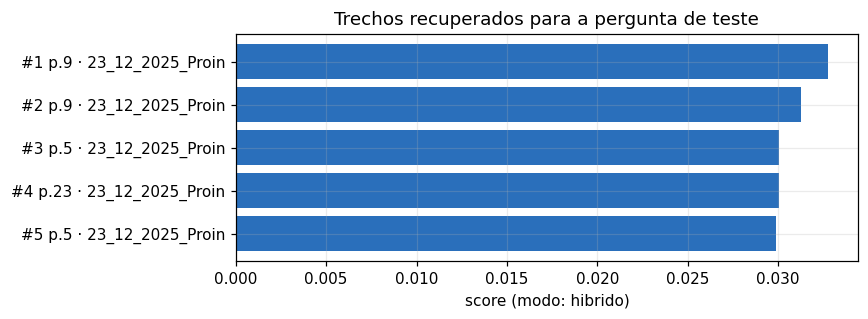

In [13]:
pergunta_teste = "Como deve ser comprovada a infraestrutura mínima do local no edital Proinfra 2025 Expansão da Finep?"

resp, trechos = responder_rag(pergunta_teste, documento="Proinfra")
print("PERGUNTA:", pergunta_teste)
print("\n--- COM RAG ---\n", resp, "\n\nFontes:", fontes_str(trechos))
print("\n--- SEM RAG ---\n", responder_sem_rag(pergunta_teste))

display(pd.DataFrame([{"#": i+1, "arquivo": t["arquivo"], "página": t["pagina"], "seção": t["secao"][:60],
                       "score": round(t["score"], 4)} for i, t in enumerate(trechos)]))

plt.figure(figsize=(8, 3))
rotulos_t = [f"#{i+1} p.{t['pagina']} · {t['arquivo'][:16]}" for i, t in enumerate(trechos)]
plt.barh(rotulos_t[::-1], [t["score"] for t in trechos][::-1], color="#2a6fbb")
plt.xlabel(f"score (modo: {MODO_BUSCA})"); plt.title("Trechos recuperados para a pergunta de teste")
plt.tight_layout(); plt.show()

## 9. Avaliação: gabarito, métricas e nota manual
### Por que mudou
Na v1, os padrões (regex) eram genéricos ("despesa", "critério") e passavam com respostas vagas, então RAG e sem RAG empataram sem que isso significasse algo. Agora:

1. **Cada pergunta cita o edital** e filtra a busca por ele (`documento`), eliminando a ambiguidade entre os três editais.
2. **Gabarito específico:** `padrao` (regex da resposta exata, ex.: a data) e/ou `paginas` (onde a resposta está).
3. **Perguntas sem resposta no edital** (`sem_resposta=True`): o sistema correto deve dizer que não encontrou; um LLM sem RAG tende a inventar.
4. **Nota manual** (1 / 0,5 / 0) pela interface da seção 9.4: é a métrica principal. A automática (regex) é complementar.
5. **MRR** além de Hit@k.

### Como montar o gabarito (9.1 e 9.2)
Para cada pergunta: use `procurar()` / `explorar()` para achar a resposta no edital, **confira no PDF** e preencha `gabarito`, `padrao` e (opcional) `paginas`. Mire em **20 a 30 perguntas**.

### 9.1 Ferramentas para achar a resposta no edital

In [14]:
def procurar(padrao, documento=None, contexto=100, max_res=15):
    """Busca textual (regex) nas páginas dos editais. Ex.: procurar(r'meses', 'CT_MCTI')"""
    n = 0
    for pg in paginas:
        if not casa_doc(pg["arquivo"], documento):
            continue
        for m in re.finditer(padrao, pg["texto"], flags=re.I):
            ini, fim = max(0, m.start() - contexto), min(len(pg["texto"]), m.end() + contexto)
            trecho = pg["texto"][ini:fim].replace("\n", " ")
            print(f"[{pg['arquivo'][:35]} | p.{pg['pagina']}] ...{trecho}...")
            n += 1
            if n >= max_res:
                return
    if n == 0:
        print("Nada encontrado.")

def explorar(pergunta, documento=None, k=5, modo="hibrido"):
    """Mostra os trechos que o sistema recuperaria para a pergunta."""
    for i, t in enumerate(INDICE.buscar(pergunta, k=k, documento=documento, modo=modo)):
        print(f"#{i+1} [{t['arquivo'][:35]} | p.{t['pagina']}] score={t['score']:.3f}\n{t['texto'][:350]}...\n")

# Exemplos (descomente para usar):
# procurar(r"vig[êe]ncia|execu[çc][ãa]o", "CT_MCTI")
# procurar(r"R\$\s?[\d\.\,]+", "Proinfra")
# explorar("prazo máximo de execução dos projetos", "CT_MCTI")

### 9.2 Perguntas e gabarito
O gabarito abaixo foi **conferido contra o texto dos três PDFs** (extraído com o mesmo método do notebook): cada pergunta traz a resposta correta (`gabarito`), um regex para checar a resposta (`padrao`) e a(s) **página(s)** onde a resposta está (`paginas`). A recuperação é medida pela **página** (Hit@k), o que é mais justo do que procurar uma palavra no trecho.

Campos de `Q(...)`: `id`, `categoria`, `pergunta`, `documento` (parte do nome do PDF), `gabarito`, `padrao`, `paginas`, `sem_resposta` e `ausente` (regex que **não** pode aparecer no edital, para provar que a pergunta não tem resposta).

Observações sobre o conjunto:
- Há **pares de perguntas parecidas com respostas diferentes** (ex.: `e1_prazo` × `e1_cadastro`: prazo da *proposta* × prazo do *cadastro*, na mesma tabela de cronograma) e **a mesma pergunta em editais diferentes** (`*_ajustes`: 48 horas, 72 horas e 5 dias úteis). São os casos em que RAG costuma errar.
- Há **perguntas de tabela** (`e2_doutores`, `e3_inpe`).
- Para acrescentar perguntas, copie uma linha `Q(...)`, use `procurar()` para achar a resposta e **confira no PDF**.

In [15]:
def Q(id, categoria, pergunta, documento, gabarito="", padrao=None, paginas=None, sem_resposta=False, ausente=None):
    return dict(id=id, categoria=categoria, pergunta=pergunta, documento=documento, gabarito=gabarito,
                padrao=padrao, paginas=paginas, sem_resposta=sem_resposta, ausente=ausente)

T1 = "a Carta Convite MCTI/Finep/FNDCT Proinfra 2025 – Unidades de Pesquisa MCTI"
T2 = "a Chamada Pública MCTI/Finep/FNDCT Proinfra 2025 Expansão"
T3 = "a Carta Convite MCTI/Finep/FNDCT Manutenção das Unidades de Pesquisa MCTI (Proinfra 2026)"

PERGUNTAS = [
    # ---- Edital 1: Carta Convite Proinfra 2025 – Unidades de Pesquisa MCTI (07_02_2025_CT_MCTI2025_Edital.pdf) ----
    Q("e1_prazo", "Prazos", f"Qual é a data limite para envio eletrônico da proposta em {T1}?", "CT_MCTI",
      gabarito="25/05/2025, até 17h00 (itens 7.1 e 7.3)",
      padrao=r"25/05/2025", paginas=[14]),
    Q("e1_cadastro", "Prazos", f"Qual é a data limite para envio do cadastro na Plataforma Finep–SISGON em {T1}?", "CT_MCTI",
      gabarito="08/04/2025, até 17h00 (item 7.1 e 7.2). Atenção: é diferente do prazo da proposta",
      padrao=r"08/04/2025", paginas=[14]),
    Q("e1_valor_total", "Valores", f"Qual é o limite de recursos do FNDCT comprometidos em {T1}?", "CT_MCTI",
      gabarito="R$ 200.000.000,00 (item 5.1)",
      padrao=r"200\.000\.000|200 milh", paginas=[13]),
    Q("e1_valor_max", "Valores", f"Qual é o valor máximo que cada ICT executora pode solicitar em {T1}?", "CT_MCTI",
      gabarito="Até R$ 15.000.000,00, em uma única proposta (item 4.1)",
      padrao=r"15\.000\.000|15 milh", paginas=[5]),
    Q("e1_exec", "Prazos", f"Qual é o prazo de execução dos projetos em {T1}?", "CT_MCTI",
      gabarito="Até 36 meses, prorrogável justificadamente (item 7.7)",
      padrao=r"(?i)36\s*(\(trinta e seis\)\s*)?meses", paginas=[14]),
    Q("e1_nordeste", "Valores", f"Qual percentual mínimo dos recursos deve ser aplicado em ICTs das regiões Norte, Nordeste e Centro-Oeste em {T1}?", "CT_MCTI",
      gabarito="No mínimo 30% (item 5.3.1)",
      padrao=r"30\s?%|trinta por cento", paginas=[13]),
    Q("e1_nota_corte", "Seleção", f"Abaixo de qual média ponderada o subprojeto é eliminado na avaliação de mérito de {T1}?", "CT_MCTI",
      gabarito="Média ponderada inferior a 3,5 (item 9.2.3)",
      padrao=r"3[,.]5", paginas=[20]),
    Q("e1_ajustes", "Processo", f"Qual é a antecedência mínima para responder aos ajustes solicitados no cadastro em {T1}?", "CT_MCTI",
      gabarito="48 horas (item 8.1.3.3)",
      padrao=r"(?i)48\s*horas", paginas=[15]),
    # ---- Edital 2: Chamada Pública Proinfra 2025 Expansão (23_12_2025_Proinfra2025Expansao_Edital.pdf) ----
    Q("e2_prazo", "Prazos", f"Qual é a data limite para envio da proposta em {T2}?", "Proinfra",
      gabarito="27/03/2026, até 17h00 (itens 15.1 e 15.3)",
      padrao=r"27/03/2026", paginas=[23]),
    Q("e2_valor_total", "Valores", f"Qual é o limite de recursos do FNDCT comprometidos em {T2}?", "Proinfra",
      gabarito="R$ 500.000.000,00 (item 4.1)",
      padrao=r"500\.000\.000|500 milh", paginas=[7]),
    Q("e2_grupo1", "Valores", f"Quanto dos recursos é destinado ao Grupo 01 (universidades e ICES) em {T2}?", "Proinfra",
      gabarito="R$ 400.000.000,00 (item 4.1.1)",
      padrao=r"400\.000\.000|400 milh", paginas=[7]),
    Q("e2_doutores", "Valores", f"Qual é o valor máximo por proposta para instituição com mais de 3.000 doutores empregados em {T2}?", "Proinfra",
      gabarito="R$ 24.000.000,00, com até 5 subprojetos (tabela do item 7.1.1)",
      padrao=r"24\.000\.000|24 milh", paginas=[13]),
    Q("e2_porte", "Requisitos", f"A partir de qual valor unitário de aquisição um equipamento é de médio ou grande porte em {T2}?", "Proinfra",
      gabarito="R$ 500.000,00 (item 2.1.11.1.1)",
      padrao=r"500\.000(?!\.)|500 mil", paginas=[3, 4]),
    Q("e2_infra", "Requisitos", f"Como deve ser comprovada a infraestrutura mínima do local de instalação dos equipamentos (Linha 1) em {T2}?", "Proinfra",
      gabarito="Por relatório fotográfico do local, conforme Anexo VII (item 5.6.3.1)",
      padrao=r"(?i)relat[óo]rio fotogr[áa]fico", paginas=[9]),
    Q("e2_contrapartida", "Contrapartida", f"Quem é isento de contrapartida em {T2}?", "Proinfra",
      gabarito="ICT federal ou instituição privada sem fins lucrativos, como proponente/convenente (item 8.3)",
      padrao=r"(?i)ICT federal|privada sem fins lucrativos|sem fins lucrativos", paginas=[14]),
    Q("e2_proj_basico", "Valores", f"Qual é o valor máximo para confecção de projeto básico ou executivo em {T2}?", "Proinfra",
      gabarito="R$ 2.400.000,00, sem exceder 10% do orçamento da obra (item 5.8.7)",
      padrao=r"2\.400\.000|2,4 milh", paginas=[12]),
    Q("e2_ajustes", "Processo", f"Qual é a antecedência mínima para responder aos ajustes solicitados no cadastro em {T2}?", "Proinfra",
      gabarito="72 horas (item 10.1.3.3)",
      padrao=r"(?i)72\s*horas", paginas=[15]),
    # ---- Edital 3: Carta Convite Manutenção – Proinfra 2026 (Edital Carta Convite Manutenção Unid. Vinc. MCTI.pdf) ----
    Q("e3_prazo", "Prazos", f"Qual é a data limite para envio eletrônico da proposta em {T3}?", "Manuten",
      gabarito="07/07/2026, até 17h00 (itens 14 e 14.1)",
      padrao=r"07/07/2026", paginas=[15]),
    Q("e3_valor_total", "Valores", f"Qual é o limite de recursos do FNDCT comprometidos em {T3}?", "Manuten",
      gabarito="R$ 100.000.000,00 (item 5.1)",
      padrao=r"100\.000\.000|100 milh", paginas=[8]),
    Q("e3_inpe", "Valores", f"Qual é o valor máximo da proposta do INPE em {T3}?", "Manuten",
      gabarito="R$ 7.000.000,00 (Grupo 1, item 7.1)",
      padrao=r"7\.000\.000|7 milh", paginas=[9]),
    Q("e3_equipamentos", "Requisitos", f"Quantos equipamentos de pesquisa, no máximo, cada proposta pode considerar em {T3}?", "Manuten",
      gabarito="20 equipamentos (item 4.7)",
      padrao=r"(?i)\b20\b|vinte", paginas=[6]),
    Q("e3_elegivel", "Requisitos", f"Qual é o valor mínimo de aquisição para um equipamento ser elegível em {T3}?", "Manuten",
      gabarito="Igual ou superior a R$ 100.000,00 (item 2.15)",
      padrao=r"100\.000(?!\.)|100 mil", paginas=[3]),
    Q("e3_contrapartida", "Contrapartida", f"Há exigência de contrapartida financeira em {T3}?", "Manuten",
      gabarito="Não será exigida (item 8.1)",
      padrao=r"(?i)n[ãa]o (ser[áa] )?exig", paginas=[10]),
    Q("e3_criterios", "Seleção", f"Quais são os critérios de avaliação de mérito e abaixo de qual média as propostas são indeferidas em {T3}?", "Manuten",
      gabarito="Relevância dos equipamentos (peso 5) e Consistência da proposta (peso 3); indeferidas com média inferior a 2,5 (item 10.3)",
      padrao=r"(?i)Relev[âa]ncia|Consist[êe]ncia|2[,.]5", paginas=[13, 14]),
    Q("e3_despesas", "Itens", f"Quais despesas correntes são apoiáveis em {T3}?", "Manuten",
      gabarito="Peças de reposição e outros materiais de consumo; serviços de terceiros PJ para manutenção, software, despesas acessórias de importação (até 20%) e operacionais/administrativas (até 5%) (item 6.1)",
      padrao=r"(?i)pe[çc]as de reposi[çc][ãa]o|material de consumo", paginas=[8]),
    Q("e3_ajustes", "Processo", f"Qual é a antecedência mínima para encaminhar os ajustes de cadastro antes do fim do prazo de envio da proposta em {T3}?", "Manuten",
      gabarito="5 (cinco) dias úteis (item 9.4)",
      padrao=r"(?i)(5|cinco)\s*(\(cinco\)\s*)?dias [úu]teis", paginas=[11]),
    # ---- Sem resposta no edital (ausência do termo conferida nos PDFs) ----
    Q("x1", "Sem resposta", f"Qual é o valor do prêmio pago ao vencedor do concurso de pitch em {T1}?", "CT_MCTI",
      gabarito="Não consta no edital", sem_resposta=True, ausente=r"(?i)pitch|pr[êe]mio"),
    Q("x2", "Sem resposta", f"Qual é o nome do reitor que assina {T3}?", "Manuten",
      gabarito="Não consta no edital", sem_resposta=True, ausente=r"(?i)reitor"),
    Q("x3", "Sem resposta", f"Qual é a taxa de juros cobrada sobre os recursos concedidos em {T2}?", "Proinfra",
      gabarito="Não consta no edital", sem_resposta=True, ausente=r"(?i)juros"),
    Q("x4", "Sem resposta", f"Qual é o prazo de carência para início do pagamento do apoio em {T3}?", "Manuten",
      gabarito="Não consta no edital", sem_resposta=True, ausente=r"(?i)car[êe]ncia"),
]

n_sr = sum(q["sem_resposta"] for q in PERGUNTAS)
print(f"{len(PERGUNTAS)} perguntas · {len(PERGUNTAS) - n_sr} com gabarito · {n_sr} sem resposta no edital")
print(pd.Series([q["categoria"] for q in PERGUNTAS]).value_counts().to_string())

30 perguntas · 26 com gabarito · 4 sem resposta no edital
Valores          9
Prazos           5
Sem resposta     4
Requisitos       4
Processo         3
Seleção          2
Contrapartida    2
Itens            1


### 9.2.1 Validação do gabarito
Confere, nos **seus** PDFs, se cada `padrao` aparece nas `paginas` indicadas e se as perguntas "sem resposta" realmente não têm o termo no edital. Rode sempre que alterar o gabarito. Se aparecer algum problema, corrija antes de avaliar.

In [16]:
def validar_gabarito():
    problemas = []
    for q in PERGUNTAS:
        pgs = [p for p in paginas if casa_doc(p["arquivo"], q["documento"])]
        if not pgs:
            problemas.append((q["id"], f"nenhum PDF casa com documento='{q['documento']}'")); continue
        if q["sem_resposta"]:
            if q["ausente"]:
                achou = [p["pagina"] for p in pgs if re.search(q["ausente"], p["texto"])]
                if achou:
                    problemas.append((q["id"], f"o termo aparece nas páginas {achou}: a pergunta tem resposta"))
            continue
        for n in (q["paginas"] or []):
            txt = next((p["texto"] for p in pgs if p["pagina"] == n), None)
            if txt is None:
                problemas.append((q["id"], f"a página {n} não existe nesse PDF"))
            elif not re.search(q["padrao"], txt):
                problemas.append((q["id"], f"o padrão não aparece na página {n}"))
    if problemas:
        print(f"⚠️ {len(problemas)} problema(s) no gabarito:")
        for i, m in problemas: print(f"  - {i}: {m}")
    else:
        print(f"✅ Gabarito consistente com os PDFs ({len(PERGUNTAS)} perguntas).")
    return problemas

_ = validar_gabarito()

✅ Gabarito consistente com os PDFs (30 perguntas).


### 9.3 Rodar a avaliação
Para cada LLM em `LLMS_AVALIAR` e cada pergunta: recuperação (Hit@1/3/5, MRR), resposta **com RAG** e **sem RAG**, e checagem automática. Estimativa: cerca de 15 a 20 s por pergunta por LLM local (30 perguntas ≈ 10 min por LLM). Se quiser só testar a recuperação, mude `RODAR_LLM` para `False`.

In [17]:
RODAR_LLM = True
K_MAX = 10
RE_ABST = re.compile(r"(?i)n[ãa]o (encontr|consta|h[áa] |foi poss|est[áa]|existe|menciona|informa|especifica)")

def eh_hit(q, trechos):
    """Lista de bools (trecho correto?) ou None se a pergunta não tem gabarito automático."""
    if q.get("sem_resposta"):
        return None
    if q.get("paginas"):
        return [casa_doc(t["arquivo"], q["documento"]) and t["pagina"] in q["paginas"] for t in trechos]
    if q.get("padrao"):
        return [bool(re.search(q["padrao"], t["texto"])) for t in trechos]
    return None

def metricas_recuperacao(q, trechos):
    h = eh_hit(q, trechos)
    if h is None:
        return {"hit@1": np.nan, "hit@3": np.nan, "hit@5": np.nan, "mrr": np.nan}
    r = next((i + 1 for i, x in enumerate(h) if x), None)
    return {"hit@1": float(any(h[:1])), "hit@3": float(any(h[:3])), "hit@5": float(any(h[:5])),
            "mrr": 1.0 / r if r else 0.0}

def resposta_ok(q, resp):
    if q.get("sem_resposta"):
        return float(bool(RE_ABST.search(resp)))
    if q.get("padrao"):
        return float(bool(re.search(q["padrao"], resp)))
    return np.nan

linhas = []
for nome_llm in LLMS_AVALIAR:
    for j, q in enumerate(PERGUNTAS):
        print(f"[{nome_llm}] pergunta {j+1}/{len(PERGUNTAS)}: {q['id']}", end="\r")
        t0 = time.time()
        trechos = INDICE.buscar(q["pergunta"], k=K_MAX, documento=q["documento"], modo=MODO_BUSCA)
        lin = {"llm": nome_llm, "id": q["id"], "categoria": q["categoria"], "pergunta": q["pergunta"],
               "tipo": "sem_resposta" if q["sem_resposta"] else "normal", "gabarito": q["gabarito"],
               "t_busca_s": time.time() - t0, **metricas_recuperacao(q, trechos)}
        if RODAR_LLM:
            t0 = time.time()
            r_rag = gerar(SYSTEM_RAG, montar_prompt(q["pergunta"], trechos[:TOP_K]), nome_llm)
            lin["t_rag_s"] = time.time() - t0
            r_sem = gerar(SYSTEM_SEM_RAG, q["pergunta"], nome_llm, max_new=250)
            lin.update({"resposta_rag": r_rag, "resposta_sem_rag": r_sem,
                        "ok_rag": resposta_ok(q, r_rag), "ok_sem": resposta_ok(q, r_sem),
                        "fontes_rag": fontes_str(trechos[:TOP_K])})
        linhas.append(lin)

df_res = pd.DataFrame(linhas)
CSV_RES = os.path.join(PASTA_SAIDA, "resultados_avaliacao.csv")
df_res.to_csv(CSV_RES, index=False)
print("\nConcluído. Salvo em", CSV_RES)
cols = ["llm", "id", "hit@1", "hit@3", "hit@5", "mrr"] + (["ok_rag", "ok_sem"] if RODAR_LLM else [])
display(df_res[cols])

[transformers] You seem to be using the pipelines sequentially on GPU. In order to maximize efficiency please use a dataset



Concluído. Salvo em /content/drive/MyDrive/Acadêmico/2026.2/Aprendizado de Maquína e Mineração de Dados/Trabalho 2 unidade/Trabalho Lista/resultados_rag/resultados_avaliacao.csv


,llm,id,hit@1,hit@3,hit@5,mrr,ok_rag,ok_sem
0,qwen-3b,e1_prazo,0.0,1.0,1.0,0.500000,1.0,0.0
1,qwen-3b,e1_cadastro,1.0,1.0,1.0,1.000000,1.0,0.0
2,qwen-3b,e1_valor_total,0.0,1.0,1.0,0.333333,1.0,0.0
3,qwen-3b,e1_valor_max,1.0,1.0,1.0,1.000000,1.0,0.0
4,qwen-3b,e1_exec,0.0,1.0,1.0,0.333333,1.0,0.0
5,qwen-3b,e1_nordeste,1.0,1.0,1.0,1.000000,1.0,1.0
6,qwen-3b,e1_nota_corte,1.0,1.0,1.0,1.000000,0.0,0.0
7,qwen-3b,e1_ajustes,0.0,1.0,1.0,0.500000,1.0,0.0
8,qwen-3b,e2_prazo,0.0,1.0,1.0,0.500000,1.0,0.0
9,qwen-3b,e2_valor_total,0.0,1.0,1.0,0.500000,1.0,0.0


### 9.4 Avaliação manual (métrica principal)
Para cada pergunta aparecem as **duas respostas lado a lado** e o gabarito. Dê a nota de cada uma:

- **1** = correta e específica do edital
- **0,5** = parcial (certa em parte, ou certa mas incompleta)
- **0** = errada, genérica ou inventada

Para a pergunta `sem_resposta`, a resposta ideal é admitir que o edital não traz a informação (nota 1). As notas são salvas automaticamente em `notas_manuais.csv`, então dá para parar e continuar depois. *(Se rodarem a avaliação de novo com respostas diferentes, apaguem esse arquivo.)*

In [18]:
import ipywidgets as widgets
from IPython.display import display, Markdown, clear_output

NOTAS_CSV = os.path.join(PASTA_SAIDA, "notas_manuais.csv")
VALORES = [1.0, 0.5, 0.0]
OPCOES = [("1 – correta e específica", 1.0), ("0,5 – parcial", 0.5), ("0 – errada / genérica / inventada", 0.0)]

df_res["nota_rag"] = np.nan
df_res["nota_sem"] = np.nan
if os.path.exists(NOTAS_CSV):
    prev = pd.read_csv(NOTAS_CSV).set_index(["llm", "id"])
    for i, r in df_res.iterrows():
        if (r["llm"], r["id"]) in prev.index:
            df_res.loc[i, ["nota_rag", "nota_sem"]] = prev.loc[(r["llm"], r["id"]), ["nota_rag", "nota_sem"]].values

def _pre(txt):
    return f"<pre style='white-space:pre-wrap;font-family:inherit;margin:4px 0'>{html.escape(str(txt))}</pre>"

w_info, w_rag, w_sem, w_msg = widgets.HTML(), widgets.HTML(), widgets.HTML(), widgets.HTML()
r_rag = widgets.RadioButtons(options=OPCOES, index=None, description="Nota RAG:", layout=widgets.Layout(width="420px"))
r_sem = widgets.RadioButtons(options=OPCOES, index=None, description="Nota sem RAG:", layout=widgets.Layout(width="420px"))
b_ant = widgets.Button(description="◀ Anterior")
b_prox = widgets.Button(description="Salvar e próxima ▶", button_style="success")
est = {"i": next((i for i, v in enumerate(df_res["nota_rag"]) if pd.isna(v)), len(df_res))}

def mostrar():
    i = est["i"]
    if i >= len(df_res):
        w_info.value = "<b>✅ Todas as respostas foram avaliadas. Rode a próxima célula para ver os gráficos.</b>"
        w_rag.value = w_sem.value = ""
        return
    r = df_res.iloc[i]
    gab = r["gabarito"] if r["gabarito"] else "(sem gabarito: leia o edital e confira)"
    w_info.value = (f"<b>({i+1}/{len(df_res)}) [{r['llm']}] {html.escape(r['categoria'])}</b><br>"
                    f"{html.escape(r['pergunta'])}<br><i>Gabarito: {html.escape(gab)}</i>")
    w_rag.value = "<b>COM RAG</b>" + _pre(r["resposta_rag"]) + f"<small>Fontes: {html.escape(r['fontes_rag'])}</small>"
    w_sem.value = "<b>SEM RAG</b>" + _pre(r["resposta_sem_rag"])
    r_rag.index = None if pd.isna(r["nota_rag"]) else VALORES.index(r["nota_rag"])
    r_sem.index = None if pd.isna(r["nota_sem"]) else VALORES.index(r["nota_sem"])
    w_msg.value = ""

def salvar():
    df_res[["llm", "id", "nota_rag", "nota_sem"]].to_csv(NOTAS_CSV, index=False)

def ao_proxima(_):
    if est["i"] >= len(df_res):
        return
    if r_rag.value is None or r_sem.value is None:
        w_msg.value = "<span style='color:#c00'>Selecione as duas notas.</span>"
        return
    idx = df_res.index[est["i"]]
    df_res.at[idx, "nota_rag"], df_res.at[idx, "nota_sem"] = r_rag.value, r_sem.value
    salvar()
    est["i"] += 1
    mostrar()

def ao_anterior(_):
    est["i"] = max(0, est["i"] - 1)
    mostrar()

b_prox.on_click(ao_proxima); b_ant.on_click(ao_anterior)
mostrar()
if RODAR_LLM:
    display(widgets.VBox([w_info, w_rag, r_rag, w_sem, r_sem, widgets.HBox([b_ant, b_prox]), w_msg]))
else:
    print("RODAR_LLM=False: não há respostas para avaliar manualmente.")

### 9.5 Resultados e gráficos
Usa a **nota manual** quando existir e, na falta dela, a checagem automática. Os gráficos são salvos no Drive (`fig_avaliacao.png`) para os slides.

30 avaliações · 30 com nota manual · 26 com gabarito automático de recuperação



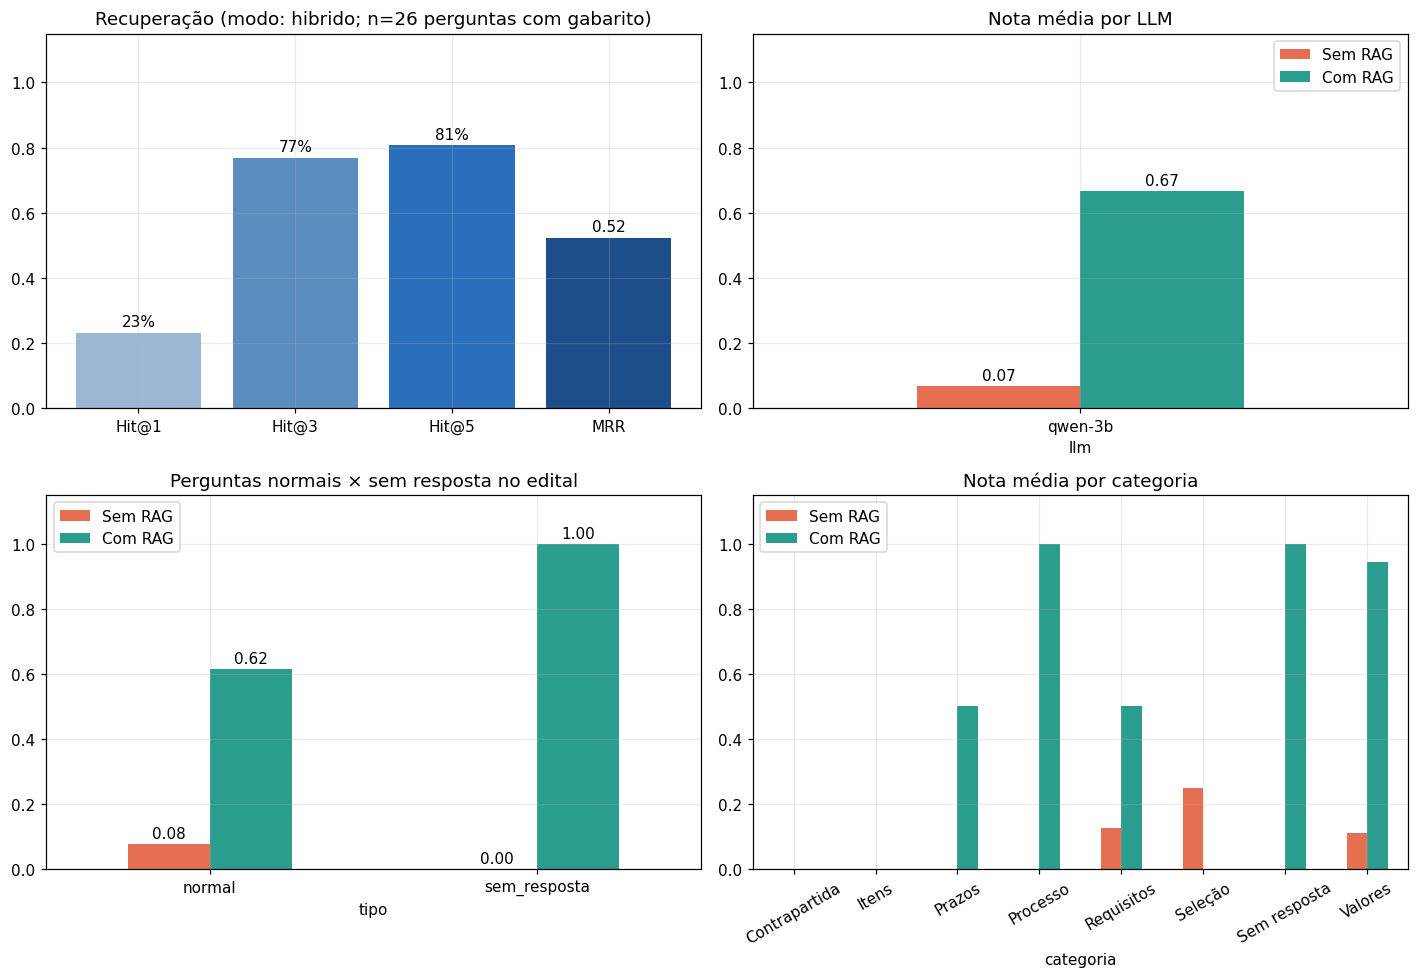

Tempo médio de busca: 17.7 ms
llm
qwen-3b    3.92


In [19]:
for t in ("rag", "sem"):
    df_res[f"score_{t}"] = df_res[f"nota_{t}"].where(df_res[f"nota_{t}"].notna(), df_res[f"ok_{t}"])

n_man = int(df_res["nota_rag"].notna().sum())
print(f"{len(df_res)} avaliações · {n_man} com nota manual · "
      f"{int(df_res['hit@5'].notna().sum())} com gabarito automático de recuperação\n")

fig, ax = plt.subplots(2, 2, figsize=(13, 9))
cores_sis = ["#e76f51", "#2a9d8f"]

# (1) Recuperação
df_ret = df_res.drop_duplicates("id")
metr = ["hit@1", "hit@3", "hit@5", "mrr"]
vals = [df_ret[m].mean() for m in metr]
if not all(pd.isna(vals)):
    ax[0, 0].bar(["Hit@1", "Hit@3", "Hit@5", "MRR"], vals, color=["#9bb7d4", "#5b8ebf", "#2a6fbb", "#1d4e89"])
    for i, v in enumerate(vals):
        ax[0, 0].text(i, v + 0.02, f"{v:.0%}" if i < 3 else f"{v:.2f}", ha="center")
ax[0, 0].set_ylim(0, 1.15)
ax[0, 0].set_title(f"Recuperação (modo: {MODO_BUSCA}; n={int(df_ret['hit@5'].notna().sum())} perguntas com gabarito)")

# (2) RAG vs sem RAG por LLM
g = df_res.groupby("llm")[["score_sem", "score_rag"]].mean()
g.plot(kind="bar", ax=ax[0, 1], color=cores_sis, rot=0)
ax[0, 1].set_ylim(0, 1.15); ax[0, 1].set_title("Nota média por LLM"); ax[0, 1].legend(["Sem RAG", "Com RAG"])
for c in ax[0, 1].containers: ax[0, 1].bar_label(c, fmt="%.2f", padding=2)

# (3) Normais vs sem resposta
g2 = df_res.groupby("tipo")[["score_sem", "score_rag"]].mean()
g2.plot(kind="bar", ax=ax[1, 0], color=cores_sis, rot=0)
ax[1, 0].set_ylim(0, 1.15); ax[1, 0].set_title("Perguntas normais × sem resposta no edital"); ax[1, 0].legend(["Sem RAG", "Com RAG"])
for c in ax[1, 0].containers: ax[1, 0].bar_label(c, fmt="%.2f", padding=2)

# (4) Por categoria
g3 = df_res.groupby("categoria")[["score_sem", "score_rag"]].mean()
g3.plot(kind="bar", ax=ax[1, 1], color=cores_sis, rot=30)
ax[1, 1].set_ylim(0, 1.15); ax[1, 1].set_title("Nota média por categoria"); ax[1, 1].legend(["Sem RAG", "Com RAG"])

plt.tight_layout()
plt.savefig(os.path.join(PASTA_SAIDA, "fig_avaliacao.png"), dpi=200, bbox_inches="tight")
plt.show()

print(f"Tempo médio de busca: {df_res['t_busca_s'].mean()*1000:.1f} ms")
print(df_res.groupby("llm")["t_rag_s"].mean().round(2).rename("tempo médio RAG (s)").to_string())
df_res.to_csv(CSV_RES, index=False)

### 9.6 Análise de erros
Perguntas em que o RAG não tirou nota máxima: separa **falha de recuperação** (o trecho certo nem foi buscado) de **falha de geração** (o trecho veio, mas a resposta saiu errada). Material para o slide de "demonstração com erro".

In [20]:
falhas = df_res[df_res["score_rag"] < 1]
print(f"{len(falhas)} avaliação(ões) com RAG abaixo de 1.\n")
for _, r in falhas.iterrows():
    if pd.isna(r["hit@5"]):
        diag = "sem gabarito de recuperação (confira os trechos com explorar())"
    elif r["hit@5"] == 0:
        diag = "falha na RECUPERAÇÃO (trecho correto fora do top-5)"
    else:
        diag = "recuperou o trecho, mas a GERAÇÃO falhou"
    print(f"[{r['llm']}] {r['id']} · {r['pergunta']}")
    print(f"  Diagnóstico: {diag}")
    print(f"  Gabarito: {r['gabarito'] or '-'}")
    print(f"  RAG: {str(r['resposta_rag'])[:350]}\n" + "-" * 80)

12 avaliação(ões) com RAG abaixo de 1.

[qwen-3b] e1_prazo · Qual é a data limite para envio eletrônico da proposta em a Carta Convite MCTI/Finep/FNDCT Proinfra 2025 – Unidades de Pesquisa MCTI?
  Diagnóstico: recuperou o trecho, mas a GERAÇÃO falhou
  Gabarito: 25/05/2025, até 17h00 (itens 7.1 e 7.3)
  RAG: A data limite para envio eletrônico da proposta foi 25/05/2025 [arquivo, p.14].
--------------------------------------------------------------------------------
[qwen-3b] e1_cadastro · Qual é a data limite para envio do cadastro na Plataforma Finep–SISGON em a Carta Convite MCTI/Finep/FNDCT Proinfra 2025 – Unidades de Pesquisa MCTI?
  Diagnóstico: recuperou o trecho, mas a GERAÇÃO falhou
  Gabarito: 08/04/2025, até 17h00 (item 7.1 e 7.2). Atenção: é diferente do prazo da proposta
  RAG: A data limite para envio do cadastro na Plataforma Finep-SISGON foi 08/04/2025 [arquivo, p.1].
--------------------------------------------------------------------------------
[qwen-3b] e1_nota_cort

## 10. Ablação da recuperação
Mede só a **recuperação** (sem LLM, rápido e sem custo), usando as perguntas com gabarito automático.

- **10.1** compara os modos de busca: `vetorial`, `bm25`, `hibrido`, `hibrido+rerank`.
- **10.2** compara o **tamanho do trecho × modelo de embedding** (modo vetorial).

> Se o gabarito for por `padrao` (regex), trechos maiores têm mais chance de conter o padrão e levam vantagem artificial. O gabarito por `paginas` é mais justo para comparar tamanhos de trecho.

26 perguntas com gabarito automático de recuperação.


config.json:   0%|          | 0.00/891 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  471MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/435 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

,hit@1,hit@3,hit@5,mrr
vetorial,0.346,0.692,0.846,0.559
bm25,0.115,0.769,0.923,0.465
hibrido,0.231,0.769,0.808,0.523
hibrido+rerank,0.846,0.962,1.000,0.901


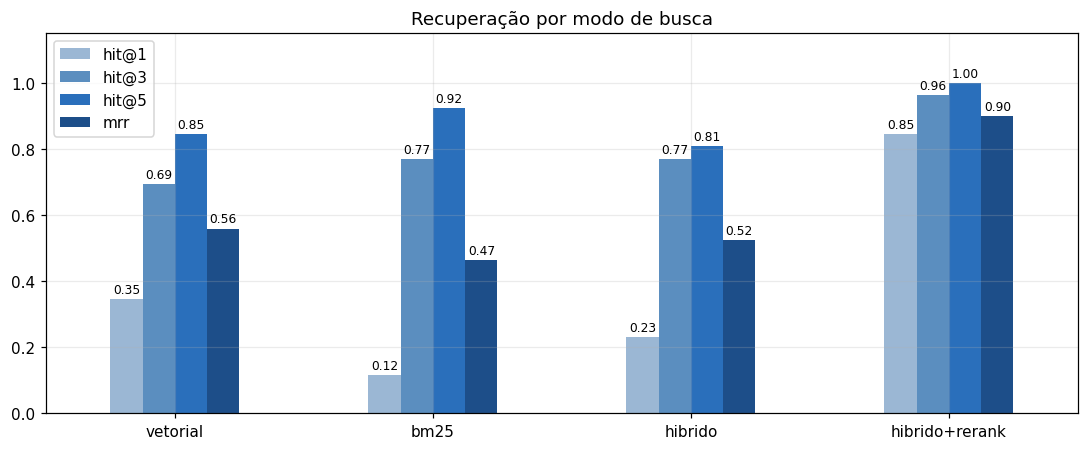

In [21]:
PERG_GAB = [q for q in PERGUNTAS if (q["paginas"] or q["padrao"]) and not q["sem_resposta"]]
print(f"{len(PERG_GAB)} perguntas com gabarito automático de recuperação.")
if len(PERG_GAB) < 5:
    print("⚠️ Poucas perguntas: os números abaixo são frágeis. Preencham mais gabaritos (seção 9.2).")

def avaliar_recuperacao(indice, modo):
    linhas = [metricas_recuperacao(q, indice.buscar(q["pergunta"], k=10, documento=q["documento"], modo=modo))
              for q in PERG_GAB]
    return pd.DataFrame(linhas).mean()

if PERG_GAB:
    df_est = pd.DataFrame({m: avaliar_recuperacao(INDICE, m) for m in MODOS}).T
    display(df_est.round(3))
    ax = df_est[["hit@1", "hit@3", "hit@5", "mrr"]].plot(kind="bar", figsize=(10, 4.2), rot=0,
                                                        color=["#9bb7d4", "#5b8ebf", "#2a6fbb", "#1d4e89"])
    ax.set_ylim(0, 1.15); ax.set_title("Recuperação por modo de busca")
    for c in ax.containers: ax.bar_label(c, fmt="%.2f", padding=2, fontsize=8)
    plt.tight_layout()
    plt.savefig(os.path.join(PASTA_SAIDA, "fig_ablacao_modos.png"), dpi=200, bbox_inches="tight")
    plt.show()

modules.json:   0%|          | 0.00/387 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/498k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/57.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/655 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  471MB            

model.safetensors: downloading bytes:           |  0.00B            

... (9 outputs left out)

Batches:   0%|          | 0/17 [00:00<?, ?it/s]

Batches:   0%|          | 0/9 [00:00<?, ?it/s]

Batches:   0%|          | 0/6 [00:00<?, ?it/s]

,modelo,chunk,n_chunks,hit@1,hit@3,hit@5,mrr
0,multilingual-e5-small,500,534,0.423,0.769,0.769,0.612
1,multilingual-e5-small,1000,267,0.231,0.615,0.692,0.434
2,multilingual-e5-small,1500,181,0.346,0.654,0.769,0.517
3,multilingual-e5-base,500,534,0.500,0.731,0.962,0.665
4,multilingual-e5-base,1000,267,0.346,0.692,0.846,0.559
5,multilingual-e5-base,1500,181,0.500,0.731,0.885,0.650


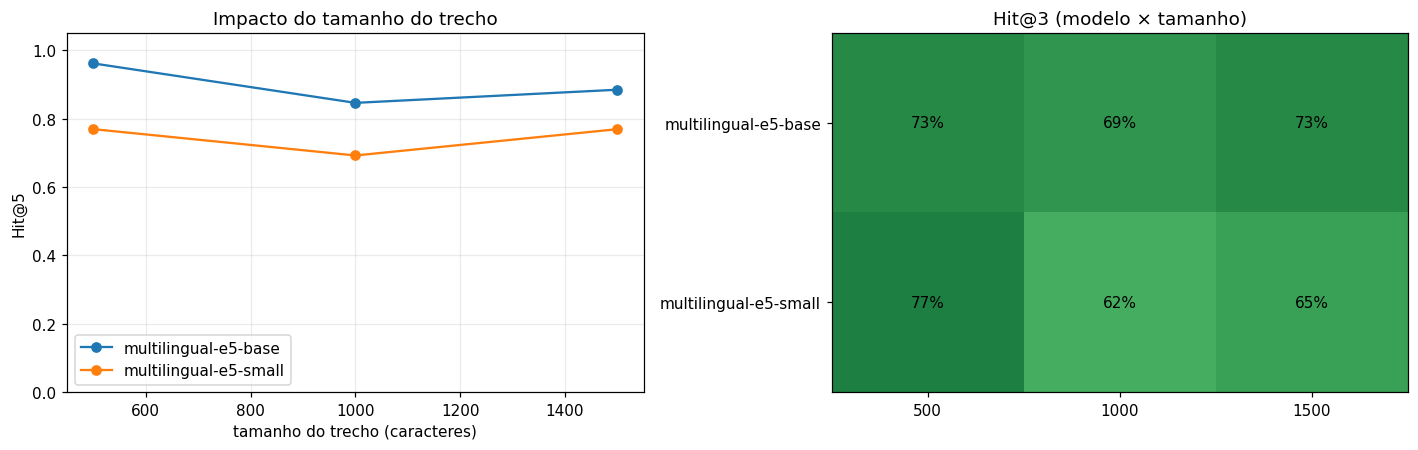

In [22]:
TAMANHOS = [500, 1000, 1500]
MODELOS  = ["intfloat/multilingual-e5-small", "intfloat/multilingual-e5-base"]

if PERG_GAB:
    linhas = []
    for modelo in MODELOS:
        for tam in TAMANHOS:
            ch = criar_chunks(paginas, tam, int(tam * 0.2))
            idx = IndiceVetorial(ch, modelo)
            linhas.append({"modelo": modelo.split("/")[-1], "chunk": tam, "n_chunks": len(ch),
                           **avaliar_recuperacao(idx, "vetorial").to_dict()})
    df_abl = pd.DataFrame(linhas)
    display(df_abl.round(3))

    fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
    for modelo, g in df_abl.groupby("modelo"):
        ax[0].plot(g["chunk"], g["hit@5"], marker="o", label=modelo)
    ax[0].set_xlabel("tamanho do trecho (caracteres)"); ax[0].set_ylabel("Hit@5")
    ax[0].set_ylim(0, 1.05); ax[0].set_title("Impacto do tamanho do trecho"); ax[0].legend()

    piv = df_abl.pivot(index="modelo", columns="chunk", values="hit@3")
    ax[1].imshow(piv.values, cmap="YlGn", vmin=0, vmax=1, aspect="auto")
    ax[1].set_xticks(range(len(piv.columns))); ax[1].set_xticklabels(piv.columns)
    ax[1].set_yticks(range(len(piv.index))); ax[1].set_yticklabels(piv.index)
    for i in range(piv.shape[0]):
        for j in range(piv.shape[1]):
            ax[1].text(j, i, f"{piv.values[i, j]:.0%}", ha="center", va="center")
    ax[1].grid(False); ax[1].set_title("Hit@3 (modelo × tamanho)")
    plt.tight_layout()
    plt.savefig(os.path.join(PASTA_SAIDA, "fig_ablacao_chunks.png"), dpi=200, bbox_inches="tight")
    plt.show()

## 11. Interface de perguntas
Escolha o edital, o **modo de busca** e o **LLM**, digite a pergunta e veja resposta, fontes, trechos usados e gráfico de relevância. Marque a opção de comparação para ver também a resposta **sem RAG**.

In [26]:
dd_doc = widgets.Dropdown(options=["Todos os editais"] + DOCS, description="Edital:", layout=widgets.Layout(width="650px"))
txt = widgets.Textarea(placeholder="Ex.: Qual a data limite para submissão das propostas?",
                       description="Pergunta:", layout=widgets.Layout(width="650px", height="80px"))
dd_modo = widgets.Dropdown(options=MODOS, value=MODO_BUSCA, description="Busca:")
dd_llm = widgets.Dropdown(options=list(LLMS), value=LLM_PADRAO, description="LLM:")
sl_k = widgets.IntSlider(value=TOP_K, min=1, max=10, description="Top-k:")
chk = widgets.Checkbox(value=False, description="Comparar com LLM sem RAG")
btn = widgets.Button(description="Perguntar", button_style="primary", icon="search")
out = widgets.Output()

def ao_clicar(_):
    pergunta = txt.value.strip()
    with out:
        clear_output()
        if not pergunta:
            print("Digite uma pergunta."); return
        doc = None if dd_doc.value == "Todos os editais" else dd_doc.value
        print("Buscando e gerando resposta...")
        try:
            resp, trechos = responder_rag(pergunta, k=sl_k.value, documento=doc, modo=dd_modo.value, llm=dd_llm.value)
            resp_sem = responder_sem_rag(pergunta, llm=dd_llm.value) if chk.value else None
        except Exception as e:
            clear_output(); print("Erro:", e); return
        clear_output()
        display(Markdown("### Resposta (com RAG)"))
        display(widgets.HTML(_pre(resp) + f"<small><b>Fontes:</b> {html.escape(fontes_str(trechos))}</small>"))
        if resp_sem:
            display(Markdown("### Resposta (sem RAG, sem acesso ao edital)"))
            display(widgets.HTML(_pre(resp_sem)))
        display(Markdown("### Trechos recuperados"))
        display(pd.DataFrame([{"#": i+1, "arquivo": t["arquivo"], "página": t["pagina"], "seção": t["secao"][:70],
                               "score": round(t["score"], 4)} for i, t in enumerate(trechos)]))
        fig, ax = plt.subplots(figsize=(7, 0.6 + 0.45 * len(trechos)))
        ax.barh([f"#{i+1} p.{t['pagina']} · {t['arquivo'][:18]}" for i, t in enumerate(trechos)][::-1],
                [t["score"] for t in trechos][::-1], color="#2a6fbb")
        ax.set_xlabel(f"score ({dd_modo.value})"); ax.set_title("Relevância dos trechos")
        plt.tight_layout(); plt.show()
        display(Markdown("### Texto dos trechos"))
        for i, t in enumerate(trechos):
            acc = widgets.Accordion(children=[widgets.HTML(_pre(t["texto"]))], selected_index=None)
            acc.set_title(0, f"#{i+1} · {t['arquivo'][:40]} · p.{t['pagina']} · score {t['score']:.3f}")
            display(acc)

btn.on_click(ao_clicar)
display(widgets.VBox([dd_doc, txt, widgets.HBox([dd_modo, dd_llm]), widgets.HBox([sl_k, chk]), btn, out]))

## 12. Resumo e conclusões
A célula abaixo monta a tabela-resumo com os números reais (salva em CSV) para colar nos slides.

In [24]:
resumo = []
for nome_llm, g in df_res.groupby("llm"):
    resumo.append({
        "LLM": nome_llm,
        "nº perguntas": len(g),
        "nota média COM RAG": round(g["score_rag"].mean(), 3),
        "nota média SEM RAG": round(g["score_sem"].mean(), 3),
        "ganho do RAG": round(g["score_rag"].mean() - g["score_sem"].mean(), 3),
        "Hit@5": round(g["hit@5"].mean(), 3),
        "MRR": round(g["mrr"].mean(), 3),
        "tempo médio RAG (s)": round(g["t_rag_s"].mean(), 1),
    })
df_resumo = pd.DataFrame(resumo)
df_resumo.to_csv(os.path.join(PASTA_SAIDA, "resumo_resultados.csv"), index=False)
display(df_resumo)
print("Arquivos em", PASTA_SAIDA, ":", sorted(os.listdir(PASTA_SAIDA)))

,LLM,nº perguntas,nota média COM RAG,nota média SEM RAG,ganho do RAG,Hit@5,MRR,tempo médio RAG (s)
0,qwen-3b,30,0.667,0.067,0.6,0.808,0.523,3.9


Arquivos em /content/drive/MyDrive/Acadêmico/2026.2/Aprendizado de Maquína e Mineração de Dados/Trabalho 2 unidade/Trabalho Lista/resultados_rag : ['fig_ablacao_chunks.png', 'fig_ablacao_modos.png', 'fig_atencao.png', 'fig_avaliacao.png', 'fig_embeddings.png', 'fig_exploratoria.png', 'notas_manuais.csv', 'resultados_avaliacao.csv', 'resumo_resultados.csv']


### Conclusões
*(Preencham com os números da tabela acima depois da avaliação manual.)*

- **Resultado principal:** nota média sem RAG = __, com RAG = __ (ganho de __). Nas perguntas **sem resposta no edital**: sem RAG = __, com RAG = __.
- **Recuperação:** Hit@5 = __%, MRR = __. Melhor modo de busca: ____ (vetorial × BM25 × híbrido × reranker).
- **Tamanho do modelo:** comparação entre ____ e ____: ____.
- **Onde o sistema falha:** (ex.: tabelas/cronogramas mal extraídos, vocabulário diferente da pergunta, perguntas que combinam várias seções).
- **Limitações:** extração de PDF, número de perguntas, avaliação manual por poucos avaliadores, LLM pequeno.
- **Trabalhos futuros:** OCR para páginas escaneadas, tratamento dedicado de tabelas, LLM maior, filtro automático do edital pela pergunta.

**Referências**
- Vaswani et al. (2017). *Attention Is All You Need.*
- Devlin et al. (2018). *BERT: Pre-training of Deep Bidirectional Transformers.*
- Lewis et al. (2020). *Retrieval-Augmented Generation for Knowledge-Intensive NLP Tasks.*
- Reimers & Gurevych (2019). *Sentence-BERT.*
- Wang et al. (2022). *Text Embeddings by Weakly-Supervised Contrastive Pre-training* (E5).
- Souza et al. (2020). *BERTimbau: pretrained BERT models for Brazilian Portuguese.*
- Robertson & Zaragoza (2009). *The Probabilistic Relevance Framework: BM25 and Beyond.*
- Cormack et al. (2009). *Reciprocal Rank Fusion outperforms Condorcet and individual rank learning methods.*